# 🛰️ Temporal Bare Soil Detection — Sequence Transformer

**Architecture:** Pixel-level Temporal Transformer (seq2seq)

**Input:** One pixel × 12 months × 10 Sentinel-2 bands → shape `(12, 10)`

**Output:** Label per month → shape `(12,)` where `0=crop, 1=bare`

**Train district:** Patiala | **Test district:** Amritsar (geographic holdout)

---
### Pipeline Overview
```
Stage 1 — Pixel Alignment   : Match same pixel across all 12 months
Stage 2 — Dataset           : Yields (12,10) sequences with (12,) labels
Stage 3 — Model             : Temporal Transformer with attention visualization
Stage 4 — Evaluation        : Per-month F1 + attention heatmaps
Stage 5 — Understanding     : What did the model actually learn?
```

## 0. Setup & Imports

In [ ]:
import subprocess, sys
def pip_install(*pkgs):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], check=True)

pip_install('pyarrow', 'fastparquet', 'tqdm')
print('✅ Dependencies ready')

✅ Dependencies ready


In [ ]:
import os, gc, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED   = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')
if DEVICE == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

Device : cuda
PyTorch: 2.10.0+cu128
GPU    : Tesla T4


## 1. Paths & Config

**✏️ Edit `BASE_DIR` to match your Google Drive path.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ── ✏️  EDIT THIS ─────────────────────────────────────────────
BASE_DIR = '/content/drive/MyDrive/ILGC-V/'   # <-- update to your path
# ──────────────────────────────────────────────────────────────

PATIALA_DIR  = f'{BASE_DIR}parquet/Patiala/'
AMRITSAR_DIR = f'{BASE_DIR}parquet/Amritsar/'
ALIGNED_DIR  = f'{BASE_DIR}parquet/aligned/'
os.makedirs(ALIGNED_DIR, exist_ok=True)

# Month order — fixed canonical sequence for the model
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']
MONTH_IDX = {m: i for i, m in enumerate(MONTHS)}   # Jan=0, Dec=11

BAND_COLS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
N_BANDS   = len(BAND_COLS)   # 10
N_MONTHS  = 12

# Pixel alignment precision
# Your data has 6+ decimal places (~1m resolution)
# We round to 5 decimal places (~10m = one Sentinel-2 pixel)
# This handles tiny float differences between monthly exports
LAT_LON_DECIMALS = 5

# Model hyperparameters
D_MODEL    = 64      # transformer embedding dimension
N_HEADS    = 4       # attention heads
N_LAYERS   = 3       # transformer encoder layers
D_FF       = 128     # feedforward dimension
DROPOUT    = 0.1
BATCH_SIZE = 512
EPOCHS     = 30
LR         = 1e-3
PATIENCE   = 5       # early stopping

print('Config ready.')
print(f'Aligned data will be saved to: {ALIGNED_DIR}')

Config ready.
Aligned data will be saved to: /content/drive/MyDrive/ILGC-V/parquet/aligned/


## 2. Stage 1 — Pixel Alignment (Large-Pool Anchor Strategy)

**The core problem:** July and November have heavy cloud masking in Punjab.
These two months act as intersection bottlenecks — any pixel missing from
either month gets dropped from the final dataset.

**Why previous runs gave too few pixels:**
```
Run 1:  500K anchor →  80K survived  (July/Nov dropped ~85% of pixels)
Run 2:  417K anchor →  16K survived  (rare August/Jan bare pixels made it worse)
```

**The fix — start with a much larger pool:**
```
May has 6.9M bare pixels available. Previous runs used only 2.9% of them.
Sample 2M bare + 2M crop from May (28% of available bare pixels).
Even if July/Nov drop 85%, we still get ~600K surviving pixels.

RAM cost of anchor step : ~200MB (lat/lon/target only, no bands)
RAM cost per month chunk: ~150MB per 2M-row batch
RAM cost of final X     : ~1.4GB (600K × 12 × 10 × 4 bytes)
Total peak RAM          : ~7-8GB  ✅ within T4 limit
```

In [ ]:
import psutil

def ram_gb():
    return psutil.virtual_memory().used / 1e9

def find_parquet_file(directory, month_name):
    """Handles both capitalised (May) and lowercase (may) filenames."""
    candidates = [
        f for f in os.listdir(directory)
        if f.endswith('.parquet') and month_name.lower() in f.lower()
    ]
    if len(candidates) == 0:
        raise FileNotFoundError(f'No parquet for "{month_name}" in {directory}')
    if len(candidates) > 1:
        raise ValueError(f'Multiple matches for "{month_name}": {candidates}')
    return os.path.join(directory, candidates[0])

def make_pixel_id(lat_series, lon_series, decimals=LAT_LON_DECIMALS):
    """Vectorised pixel key from lat/lon Series. Returns a string Series."""
    fmt = f'{{:.{decimals}f}}'
    return lat_series.round(decimals).map(fmt.format) + '_' + \
           lon_series.round(decimals).map(fmt.format)


# ── Sample size config ────────────────────────────────────────
# July and November have heavy cloud masking → act as intersection bottleneck
# Previous run: 500K anchor → only 80K survived 12-month intersection
# Fix: start with a much larger pool so enough pixels survive the cloudy months
#
# Available in May: 6,951,442 bare  6,100,214 crop
# We sample 2M of each → ~400-500K expected to survive intersection
#
N_PER_CLASS_PER_ANCHOR = 2_000_000  # ✏️ reduce to 1_000_000 if OOM

est_anchor  = 2 * N_PER_CLASS_PER_ANCHOR
est_survive = int(est_anchor * 0.15)   # ~15% survive July/Nov bottleneck
est_ram     = est_survive * 12 * 10 * 4 / 1e9
print(f'Anchor pool      : {est_anchor:,} pixels (2M bare + 2M crop from May)')
print(f'Expected survival: ~{est_survive:,} pixels after 12-month intersection')
print(f'Expected X RAM   : ~{est_ram:.2f} GB')
print(f'Peak RAM during alignment: ~7-8 GB (within T4 limit)')

Anchor pool      : 4,000,000 pixels (2M bare + 2M crop from May)
Expected survival: ~600,000 pixels after 12-month intersection
Expected X RAM   : ~0.29 GB
Peak RAM during alignment: ~7-8 GB (within T4 limit)


In [ ]:
def get_anchor_pixel_ids(district_dir, n_per_class=N_PER_CLASS_PER_ANCHOR):
    """
    Sample anchor pixel IDs from May (best bare-soil coverage in Punjab).

    August and January have <10K bare pixels in Patiala — not worth anchoring.
    July/November cloud gaps are the real bottleneck. The fix is a larger
    initial sample so enough pixels survive the intersection.

    RAM cost: ~200MB (lat/lon/target only, no bands).
    Returns a set of pixel_id strings.
    """
    print(f'  Loading anchor month (May) — lat/lon/target only...')
    path = find_parquet_file(district_dir, 'May')

    df = pd.read_parquet(path, columns=['target', 'latitude', 'longitude'])
    df = df[df['target'] != 0].copy()
    df['pixel_id'] = make_pixel_id(df['latitude'], df['longitude'])

    bare_ids = df[df['target'] == 2]['pixel_id'].values
    crop_ids = df[df['target'] == 1]['pixel_id'].values
    del df; gc.collect()

    rng = np.random.default_rng(SEED)
    n_bare = min(n_per_class, len(bare_ids))
    n_crop = min(n_per_class, len(crop_ids))
    sampled_bare = set(rng.choice(bare_ids, n_bare, replace=False))
    sampled_crop = set(rng.choice(crop_ids, n_crop, replace=False))

    anchor_ids = sampled_bare | sampled_crop
    print(f'  Anchor set: {len(sampled_bare):,} bare + {len(sampled_crop):,} crop '
          f'= {len(anchor_ids):,} unique pixels')
    print(f'  Available in May: {len(bare_ids):,} bare  {len(crop_ids):,} crop')
    print(f'  RAM after anchor step: {ram_gb():.1f} GB')
    return anchor_ids


def load_month_for_anchors(district_dir, month_name, anchor_ids):
    """
    Step 2: Load one month, keep ONLY rows whose pixel_id is in anchor_ids.

    Reads in chunks of CHUNK_ROWS to avoid loading the full 43M rows at once.
    Each chunk is filtered immediately — only matching rows are kept.
    Peak RAM = one chunk (~100MB) not the full file (~3GB).

    Returns a slim DataFrame:
        pixel_id, {Month}_B2 ... {Month}_B12, label_{Month}
    """
    CHUNK_ROWS = 2_000_000   # 2M rows at a time — ~150MB per chunk

    path = find_parquet_file(district_dir, month_name)
    needed = ['target', 'latitude', 'longitude'] + BAND_COLS

    chunks_kept = []
    rows_scanned = 0

    # Read parquet in row-group chunks using pyarrow
    import pyarrow.parquet as pq
    pf = pq.ParquetFile(path)

    for batch in pf.iter_batches(batch_size=CHUNK_ROWS, columns=needed):
        chunk = batch.to_pandas()
        rows_scanned += len(chunk)

        # Filter annotated rows only
        chunk = chunk[chunk['target'] != 0]
        if len(chunk) == 0:
            del chunk; continue

        # Build pixel_id and filter to anchor set
        chunk['pixel_id'] = make_pixel_id(chunk['latitude'], chunk['longitude'])
        chunk = chunk[chunk['pixel_id'].isin(anchor_ids)]
        if len(chunk) == 0:
            del chunk; continue

        # Label + band rename
        chunk[f'label_{month_name}'] = (chunk['target'] == 2).astype(np.int8)
        band_rename = {b: f'{month_name}_{b}' for b in BAND_COLS}
        chunk = chunk.rename(columns=band_rename)

        keep = ['pixel_id'] + list(band_rename.values()) + [f'label_{month_name}']
        chunk = chunk[keep]
        for c in band_rename.values():
            chunk[c] = chunk[c].astype(np.float32)

        chunks_kept.append(chunk)
        del chunk; gc.collect()

    if len(chunks_kept) == 0:
        return pd.DataFrame()

    result = pd.concat(chunks_kept, ignore_index=True)
    # Drop duplicates (same pixel_id in multiple chunks — shouldn't happen but safety)
    result = result.drop_duplicates(subset='pixel_id')
    del chunks_kept; gc.collect()
    return result


print('Alignment functions defined.')
print('  get_anchor_pixel_ids() — samples pixel IDs from one month (tiny RAM)')
print('  load_month_for_anchors() — reads full parquet in 2M-row chunks, keeps only anchors')

Alignment functions defined.
  get_anchor_pixel_ids() — samples pixel IDs from one month (tiny RAM)
  load_month_for_anchors() — reads full parquet in 2M-row chunks, keeps only anchors


In [ ]:
def build_aligned_dataset(district_dir, district_name, save_path,
                           n_per_class=N_PER_CLASS_PER_ANCHOR):
    """
    Full alignment pipeline:
      1. Sample 2M bare + 2M crop anchor IDs from May
      2. For each of 12 months: load only anchor pixels in chunks
      3. Inner-join all 12 months on pixel_id
      4. Build X (N,12,10) and y (N,12), save to parquet
    """
    print(f'\n{"="*62}')
    print(f'  Aligning: {district_name}  (large-pool anchor strategy)')
    print(f'{"="*62}')

    # Step 1: sample large anchor pool from May
    anchor_ids = get_anchor_pixel_ids(district_dir, n_per_class=n_per_class)

    # Step 2: load each month filtered to anchor IDs
    monthly_dfs = {}
    for m_idx, month in enumerate(MONTHS):
        t0 = time.time()
        print(f'  [{m_idx+1:>2}/12] {month:<12}', end='  ')
        df_m = load_month_for_anchors(district_dir, month, anchor_ids)
        monthly_dfs[month] = df_m
        print(f'{len(df_m):>8,} rows  RAM: {ram_gb():.1f}GB  ({time.time()-t0:.0f}s)')

    # Step 3: inner-join all 12 months — these are small DataFrames now
    print('\n  Joining 12 months on pixel_id...')
    running = monthly_dfs[MONTHS[0]]
    for month in MONTHS[1:]:
        running = running.merge(monthly_dfs[month], on='pixel_id', how='inner')
        del monthly_dfs[month]; gc.collect()

    N = len(running)
    print(f'  ✅ {N:,} pixels survived 12-month intersection')
    print(f'  RAM after join: {ram_gb():.1f} GB')

    # Step 4: build arrays
    print('  Building X (N,12,10) and y (N,12)...')
    pixel_ids = running['pixel_id'].tolist()
    X = np.zeros((N, N_MONTHS, N_BANDS), dtype=np.float32)
    y = np.zeros((N, N_MONTHS),          dtype=np.int8)

    for m_idx, month in enumerate(MONTHS):
        for b_idx, band in enumerate(BAND_COLS):
            X[:, m_idx, b_idx] = running[f'{month}_{band}'].values
        y[:, m_idx] = running[f'label_{month}'].values

    print(f'  Saving to {save_path}...')
    running.to_parquet(save_path, index=False)
    del running; gc.collect()

    print(f'  ✅ Done.  X={X.shape}  y={y.shape}  RAM: {ram_gb():.1f}GB')
    return X, y, pixel_ids


print('build_aligned_dataset() ready.')

build_aligned_dataset() ready.


In [ ]:
# ── Run alignment for Patiala (train) ────────────────────────
# ⚠️  Delete old cache first — it was built with single-month anchor (May only)
#     which caused F1≈0 for January, August, December.
#     Remove these two lines after the first successful run.
import os
PATIALA_ALIGNED = f'{ALIGNED_DIR}Patiala_aligned.parquet'
if os.path.exists(PATIALA_ALIGNED):
    os.remove(PATIALA_ALIGNED)
    print('🗑️  Deleted old Patiala cache (single-month anchor).')

X_train, y_i8, pixel_ids_train = build_aligned_dataset(
    PATIALA_DIR, 'Patiala', PATIALA_ALIGNED)
y_train = y_i8.astype(np.int64)

N_train = len(X_train)
print(f'Patiala  — X={X_train.shape}  y={y_train.shape}  RAM={ram_gb():.1f}GB')

🗑️  Deleted old Patiala cache (single-month anchor).

  Aligning: Patiala  (large-pool anchor strategy)
  Loading anchor month (May) — lat/lon/target only...
  Anchor set: 2,000,000 bare + 2,000,000 crop = 4,000,000 unique pixels
  Available in May: 6,951,442 bare  6,100,214 crop
  RAM after anchor step: 3.6 GB
  [ 1/12] January       3,809,483 rows  RAM: 3.9GB  (178s)
  [ 2/12] February      3,811,785 rows  RAM: 4.3GB  (178s)
  [ 3/12] March         3,660,521 rows  RAM: 4.7GB  (179s)
  [ 4/12] April         3,429,947 rows  RAM: 5.0GB  (173s)
  [ 5/12] May           4,000,000 rows  RAM: 5.4GB  (142s)
  [ 6/12] June          2,913,838 rows  RAM: 5.9GB  (159s)
  [ 7/12] July          1,469,305 rows  RAM: 6.0GB  (92s)
  [ 8/12] August        3,918,482 rows  RAM: 6.6GB  (181s)
  [ 9/12] September     3,955,213 rows  RAM: 7.1GB  (181s)
  [10/12] October       3,457,334 rows  RAM: 7.5GB  (177s)
  [11/12] November      1,482,289 rows  RAM: 7.5GB  (138s)
  [12/12] December      3,402,580 rows 

In [ ]:
# ── Run alignment for Amritsar (test) ────────────────────────
# ⚠️  Delete old cache — same reason as Patiala above.
AMRITSAR_ALIGNED = f'{ALIGNED_DIR}Amritsar_aligned.parquet'
if os.path.exists(AMRITSAR_ALIGNED):
    os.remove(AMRITSAR_ALIGNED)
    print('🗑️  Deleted old Amritsar cache (single-month anchor).')

X_test, y_i8, pixel_ids_test = build_aligned_dataset(
    AMRITSAR_DIR, 'Amritsar', AMRITSAR_ALIGNED)
y_test = y_i8.astype(np.int64)

N_test = len(X_test)
print(f'Amritsar — X={X_test.shape}  y={y_test.shape}  RAM={ram_gb():.1f}GB')


  Aligning: Amritsar  (large-pool anchor strategy)
  Loading anchor month (May) — lat/lon/target only...
  Anchor set: 2,000,000 bare + 2,000,000 crop = 4,000,000 unique pixels
  Available in May: 30,332,357 bare  9,019,143 crop
  RAM after anchor step: 7.1 GB
  [ 1/12] January       2,885,200 rows  RAM: 6.9GB  (240s)
  [ 2/12] February      3,800,278 rows  RAM: 7.1GB  (265s)
  [ 3/12] March         3,720,341 rows  RAM: 7.2GB  (270s)
  [ 4/12] April         3,617,443 rows  RAM: 7.4GB  (264s)
  [ 5/12] May           4,000,000 rows  RAM: 7.6GB  (253s)
  [ 6/12] June          3,270,489 rows  RAM: 7.8GB  (258s)
  [ 7/12] July          3,147,865 rows  RAM: 7.9GB  (248s)
  [ 8/12] August        1,906,933 rows  RAM: 7.8GB  (141s)
  [ 9/12] September     3,973,351 rows  RAM: 8.0GB  (277s)
  [10/12] October       3,420,017 rows  RAM: 8.3GB  (268s)
  [11/12] November      2,388,079 rows  RAM: 8.3GB  (240s)
  [12/12] December      3,185,280 rows  RAM: 8.5GB  (262s)

  Joining 12 months on pixel_

## 3. EDA — Understanding the Aligned Dataset

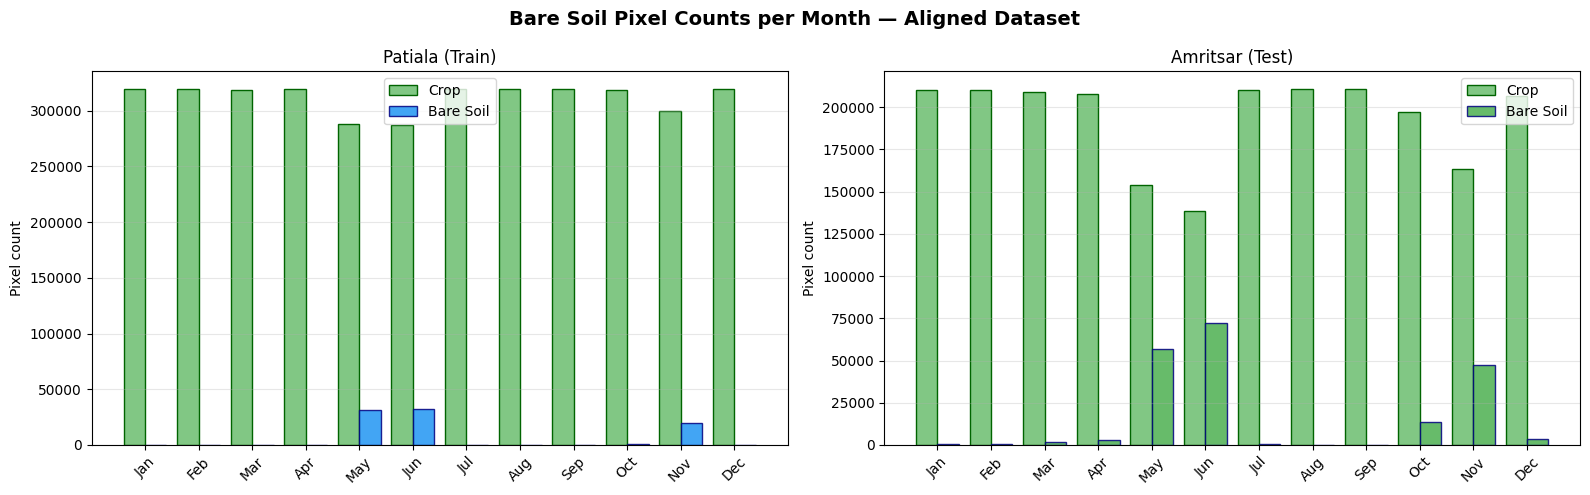

✅ This plot shows WHEN bare soil windows occur — the model must learn this pattern.


In [ ]:
# ── Class distribution per month ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Bare Soil Pixel Counts per Month — Aligned Dataset', fontsize=14, fontweight='bold')

for ax, (y_data, title, color) in zip(axes, [
    (y_train, 'Patiala (Train)', '#2196F3'),
    (y_test,  'Amritsar (Test)', '#4CAF50')
]):
    bare_counts = y_data.sum(axis=0)          # bare pixels per month
    crop_counts = (y_data == 0).sum(axis=0)   # crop pixels per month

    x = np.arange(N_MONTHS)
    w = 0.4
    ax.bar(x - w/2, crop_counts, w, label='Crop',      color='#81C784', edgecolor='darkgreen')
    ax.bar(x + w/2, bare_counts, w, label='Bare Soil', color=color,     edgecolor='navy', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([m[:3] for m in MONTHS], rotation=45)
    ax.set_title(title)
    ax.set_ylabel('Pixel count')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}eda_monthly_distribution.png', dpi=120)
plt.show()
print('✅ This plot shows WHEN bare soil windows occur — the model must learn this pattern.')

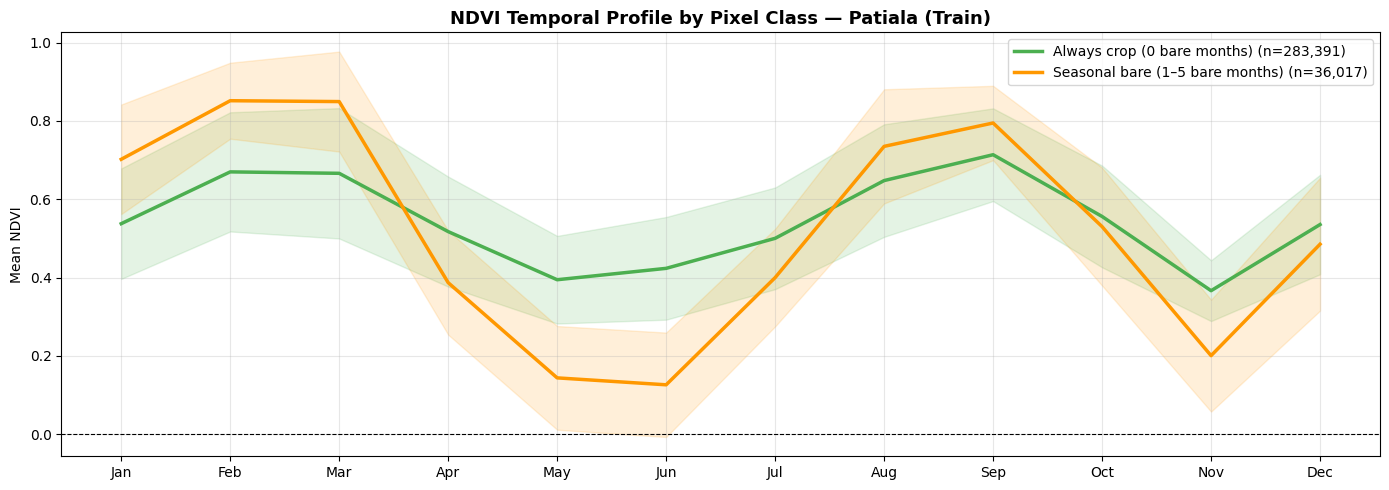

✅ This is the KEY pattern the model must learn — the NDVI drop indicates harvest → bare soil.


In [ ]:
# ── NDVI proxy over time: bare vs crop pixels ─────────────────
# NDVI ≈ (B8 - B4) / (B8 + B4)
B4_idx = BAND_COLS.index('B4')
B8_idx = BAND_COLS.index('B8')

def compute_ndvi(X):
    """X: (N, 12, 10) → NDVI: (N, 12)"""
    b4 = X[:, :, B4_idx].astype(np.float32)
    b8 = X[:, :, B8_idx].astype(np.float32)
    return (b8 - b4) / (b8 + b4 + 1e-8)

ndvi_train = compute_ndvi(X_train)   # (N, 12)

# For each pixel, find its 'dominant' class across the year
# A pixel is 'bare' dominant if it's bare in more than 3 months
bare_months_per_pixel = y_train.sum(axis=1)   # (N,)

always_crop = bare_months_per_pixel == 0
sometimes_bare = (bare_months_per_pixel > 0) & (bare_months_per_pixel < 6)
often_bare = bare_months_per_pixel >= 6

fig, ax = plt.subplots(figsize=(14, 5))

# Sample 2000 pixels from each group
rng = np.random.default_rng(SEED)

for mask, label, color, alpha in [
    (always_crop,    'Always crop (0 bare months)',     '#4CAF50', 0.7),
    (sometimes_bare, 'Seasonal bare (1–5 bare months)', '#FF9800', 0.7),
    (often_bare,     'Often bare (6+ bare months)',     '#F44336', 0.7),
]:
    idx = np.where(mask)[0]
    if len(idx) == 0:
        continue
    sample = rng.choice(idx, min(2000, len(idx)), replace=False)
    mean_ndvi = ndvi_train[sample].mean(axis=0)
    std_ndvi  = ndvi_train[sample].std(axis=0)
    ax.plot(mean_ndvi, label=f'{label} (n={len(idx):,})', color=color, linewidth=2.5)
    ax.fill_between(range(N_MONTHS), mean_ndvi - std_ndvi, mean_ndvi + std_ndvi,
                    color=color, alpha=0.15)

ax.set_xticks(range(N_MONTHS))
ax.set_xticklabels([m[:3] for m in MONTHS])
ax.set_ylabel('Mean NDVI')
ax.set_title('NDVI Temporal Profile by Pixel Class — Patiala (Train)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.tight_layout()
plt.savefig(f'{BASE_DIR}eda_ndvi_temporal_profiles.png', dpi=120)
plt.show()
print('✅ This is the KEY pattern the model must learn — the NDVI drop indicates harvest → bare soil.')

In [ ]:
# ── Summary stats ─────────────────────────────────────────────
print('─'*55)
print(f'  DATASET SUMMARY')
print('─'*55)
print(f'  Patiala  (train) : {len(X_train):>10,} aligned pixels')
print(f'  Amritsar (test)  : {len(X_test):>10,} aligned pixels')
print()
print(f'  Each pixel is a sequence: (12 months × 10 bands)')
print(f'  Each pixel has 12 labels: one per month')
print()
print(f'  Patiala — total bare labels  : {y_train.sum():>12,}')
print(f'  Patiala — total crop labels  : {(y_train==0).sum():>12,}')
print(f'  Amritsar — total bare labels : {y_test.sum():>12,}')
print(f'  Amritsar — total crop labels : {(y_test==0).sum():>12,}')
print('─'*55)

───────────────────────────────────────────────────────
  DATASET SUMMARY
───────────────────────────────────────────────────────
  Patiala  (train) :    319,408 aligned pixels
  Amritsar (test)  :    210,729 aligned pixels

  Each pixel is a sequence: (12 months × 10 bands)
  Each pixel has 12 labels: one per month

  Patiala — total bare labels  :       84,020
  Patiala — total crop labels  :    3,748,876
  Amritsar — total bare labels :      200,549
  Amritsar — total crop labels :    2,328,199
───────────────────────────────────────────────────────


## 4. Data Preparation — Scaling

**Important:** The scaler is fit on Patiala training data only, then applied to both districts.

We reshape to `(N×12, 10)` for fitting, then reshape back.

In [ ]:
# N_train and N_test are set in the loading cells above
# Flatten time for scaling: (N, 12, 10) → (N*12, 10)
X_tr_flat = X_train.reshape(-1, N_BANDS)
X_va_flat = X_test.reshape(-1, N_BANDS)

print('Fitting RobustScaler on Patiala...')
scaler = RobustScaler(quantile_range=(10.0, 90.0))
scaler.fit(X_tr_flat)

X_tr_scaled = scaler.transform(X_tr_flat).reshape(N_train, N_MONTHS, N_BANDS).astype(np.float32)
X_va_scaled = scaler.transform(X_va_flat).reshape(N_test,  N_MONTHS, N_BANDS).astype(np.float32)

del X_tr_flat, X_va_flat; gc.collect()

print(f'X_train scaled: {X_tr_scaled.shape}')
print(f'X_test  scaled: {X_va_scaled.shape}')
print(f'y_train       : {y_train.shape}')
print(f'y_test        : {y_test.shape}')

Fitting RobustScaler on Patiala...
X_train scaled: (319408, 12, 10)
X_test  scaled: (210729, 12, 10)
y_train       : (319408, 12)
y_test        : (210729, 12)


## 5. Dataset & DataLoader

In [ ]:
class TemporalPixelDataset(Dataset):
    """
    Each sample:
        x : (12, 10) float32  — 12 months × 10 Sentinel-2 bands
        y : (12,)   int64     — label per month (0=crop, 1=bare)
    """
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)            # (N, 12, 10)
        self.y = torch.from_numpy(y.astype(np.int64))  # (N, 12)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Compute class weights to handle bare/crop imbalance
n_bare = y_train.sum()
n_crop = (y_train == 0).sum()
n_total = n_bare + n_crop
w_bare = n_total / (2 * n_bare)
w_crop = n_total / (2 * n_crop)
class_weights = torch.tensor([w_crop, w_bare], dtype=torch.float32).to(DEVICE)
print(f'Class weights — crop: {w_crop:.3f}  bare: {w_bare:.3f}')

tr_ds = TemporalPixelDataset(X_tr_scaled, y_train)
va_ds = TemporalPixelDataset(X_va_scaled, y_test)

tr_loader = DataLoader(tr_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
va_loader = DataLoader(va_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f'Train batches : {len(tr_loader)}')
print(f'Val   batches : {len(va_loader)}')

Class weights — crop: 0.511  bare: 22.809
Train batches : 624
Val   batches : 412


## 6. Model — Temporal Transformer

### Architecture

```
Input: (B, 12, 10)          — batch × months × bands
  ↓
Band Projection              — Linear(10 → D_MODEL)
  ↓
Positional Encoding          — learnable month embeddings (12 positions)
  ↓
Transformer Encoder          — N_LAYERS × (Self-Attention + FFN)
  ↓                            each month attends to ALL other months
Output per timestep          — Linear(D_MODEL → 2)
  ↓
Output: (B, 12, 2)           — logits per month per class
```

**Key design choice:** We use **learnable positional encodings** (not sinusoidal).
This lets the model learn that 'January' and 'December' are adjacent in the crop cycle.

In [ ]:
class TemporalBandProjection(nn.Module):
    """Projects raw 10-band input to D_MODEL dimensions."""
    def __init__(self, n_bands, d_model):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(n_bands, d_model),
            nn.LayerNorm(d_model),
            nn.GELU()
        )
    def forward(self, x):
        return self.proj(x)   # (B, 12, D_MODEL)


class TemporalTransformer(nn.Module):
    """
    Sequence-to-sequence Temporal Transformer for bare soil detection.

    Input : (B, T, N_BANDS)   T=12 months
    Output: (B, T, 2)         logits per timestep

    Attention weights are stored in self.attn_weights after each
    forward pass with return_attention=True.
    """
    def __init__(self, n_bands=10, n_months=12, d_model=64,
                 n_heads=4, n_layers=3, d_ff=128, dropout=0.1):
        super().__init__()
        self.n_months = n_months
        self.d_model  = d_model

        # 1. Project bands → d_model
        self.input_proj = TemporalBandProjection(n_bands, d_model)

        # 2. Learnable positional encoding (one vector per month)
        self.pos_embed = nn.Embedding(n_months, d_model)

        # 3. Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=dropout,
            batch_first=True,    # (B, T, D) convention
            norm_first=True      # pre-norm: more stable training
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        # 4. Per-timestep classifier head
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, 2)   # 2 classes: crop / bare
        )

        # Storage for attention visualization
        self.attn_weights = None
        self._hooks = []

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        """
        x: (B, T, N_BANDS)
        returns: logits (B, T, 2)
        """
        B, T, _ = x.shape

        # Band projection
        z = self.input_proj(x)              # (B, T, D)

        # Add positional encoding
        pos = torch.arange(T, device=x.device).unsqueeze(0)   # (1, T)
        z = z + self.pos_embed(pos)         # (B, T, D)

        # Transformer — each month attends to all other months
        z = self.transformer(z)             # (B, T, D)

        # Classify each timestep
        logits = self.head(z)               # (B, T, 2)
        return logits

    def get_attention_weights(self, x):
        """
        Extract attention weights from the LAST transformer layer.
        Returns: attn (B, n_heads, T, T)
        """
        self.eval()
        B, T, _ = x.shape
        z = self.input_proj(x)
        pos = torch.arange(T, device=x.device).unsqueeze(0)
        z = z + self.pos_embed(pos)

        # Run through all layers, capture last layer's attention
        attn_output = None
        for i, layer in enumerate(self.transformer.layers):
            # Pre-norm
            z_norm = layer.norm1(z)
            if i == len(self.transformer.layers) - 1:
                # Last layer: extract attention weights
                attn_out, attn_w = layer.self_attn(
                    z_norm, z_norm, z_norm,
                    need_weights=True,
                    average_attn_weights=False   # keep per-head
                )
                attn_output = attn_w   # (B, n_heads, T, T)
            else:
                attn_out = layer.self_attn(z_norm, z_norm, z_norm, need_weights=False)[0]
            z = z + layer.dropout1(attn_out)
            z_norm = layer.norm2(z)
            z = z + layer.dropout2(layer.linear2(layer.dropout(layer.activation(layer.linear1(z_norm)))))

        return attn_output   # (B, n_heads, T, T)


# Instantiate
model = TemporalTransformer(
    n_bands=N_BANDS, n_months=N_MONTHS,
    d_model=D_MODEL, n_heads=N_HEADS,
    n_layers=N_LAYERS, d_ff=D_FF, dropout=DROPOUT
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f'Model parameters: {total_params:,}')
print(model)

Model parameters: 104,162
TemporalTransformer(
  (input_proj): TemporalBandProjection(
    (proj): Sequential(
      (0): Linear(in_features=10, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (2): GELU(approximate='none')
    )
  )
  (pos_embed): Embedding(12, 64)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)

## 7. Training

In [ ]:
def train_temporal_transformer(model, tr_loader, va_loader,
                                epochs=EPOCHS, lr=LR, patience=PATIENCE):
    """
    Trains the temporal transformer with early stopping.
    Loss: CrossEntropy weighted by class imbalance.
    Tracks per-month bare-soil F1 on validation set each epoch.
    """
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr,
        steps_per_epoch=len(tr_loader),
        epochs=epochs
    )

    history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [],   'val_f1': [],
        'val_f1_per_month': []   # list of arrays shape (12,)
    }

    best_val_f1  = 0.0
    best_weights = None
    wait         = 0

    print(f'\n{"Epoch":>6}  {"TrLoss":>8}  {"VaLoss":>8}  '
          f'{"TrF1":>7}  {"VaF1":>7}  {"Time":>6}')
    print('─' * 55)

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        # ── Train ────────────────────────────────────────────
        model.train()
        tr_loss = 0.
        tr_preds, tr_labels = [], []

        for x_batch, y_batch in tr_loader:
            x_batch = x_batch.to(DEVICE)          # (B, 12, 10)
            y_batch = y_batch.to(DEVICE)          # (B, 12)

            logits = model(x_batch)               # (B, 12, 2)

            # Reshape for loss: (B*12, 2) vs (B*12,)
            B, T, C = logits.shape
            loss = criterion(
                logits.reshape(B * T, C),
                y_batch.reshape(B * T)
            )

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()

            tr_loss += loss.item()
            preds = logits.argmax(dim=-1).cpu().numpy().flatten()  # (B*12,)
            tr_preds.append(preds)
            tr_labels.append(y_batch.cpu().numpy().flatten())

        tr_loss /= len(tr_loader)
        tr_preds  = np.concatenate(tr_preds)
        tr_labels = np.concatenate(tr_labels)
        tr_f1 = f1_score(tr_labels, tr_preds, pos_label=1, zero_division=0)

        # ── Validate ─────────────────────────────────────────
        model.eval()
        va_loss = 0.
        va_preds_all  = []   # shape will be (N_val, 12)
        va_labels_all = []

        with torch.no_grad():
            for x_batch, y_batch in va_loader:
                x_batch = x_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)
                logits  = model(x_batch)

                B, T, C = logits.shape
                loss = criterion(
                    logits.reshape(B * T, C),
                    y_batch.reshape(B * T)
                )
                va_loss += loss.item()

                preds = logits.argmax(dim=-1).cpu().numpy()   # (B, 12)
                va_preds_all.append(preds)
                va_labels_all.append(y_batch.cpu().numpy())

        va_loss /= len(va_loader)
        va_preds_all  = np.concatenate(va_preds_all,  axis=0)   # (N_val, 12)
        va_labels_all = np.concatenate(va_labels_all, axis=0)

        # Overall F1
        va_f1 = f1_score(va_labels_all.flatten(), va_preds_all.flatten(),
                         pos_label=1, zero_division=0)

        # Per-month F1  (shape: 12,)
        monthly_f1 = np.array([
            f1_score(va_labels_all[:, m], va_preds_all[:, m],
                     pos_label=1, zero_division=0)
            for m in range(N_MONTHS)
        ])

        # Log
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_f1'].append(tr_f1)
        history['val_f1'].append(va_f1)
        history['val_f1_per_month'].append(monthly_f1)

        elapsed = time.time() - t0
        marker = ''
        if va_f1 > best_val_f1:
            best_val_f1  = va_f1
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
            marker = ' ✅'
        else:
            wait += 1

        print(f'{epoch:>6}  {tr_loss:>8.4f}  {va_loss:>8.4f}  '
              f'{tr_f1:>7.4f}  {va_f1:>7.4f}  {elapsed:>5.0f}s{marker}')

        if wait >= patience:
            print(f'\nEarly stopping at epoch {epoch}.')
            break

    # Restore best weights
    model.load_state_dict(best_weights)
    print(f'\nBest val bare-soil F1: {best_val_f1:.4f}')
    return model, history, best_val_f1


print('Training function defined.')

Training function defined.


In [ ]:
model, history, best_f1 = train_temporal_transformer(
    model, tr_loader, va_loader,
    epochs=EPOCHS, lr=LR, patience=PATIENCE
)


 Epoch    TrLoss    VaLoss     TrF1     VaF1    Time
───────────────────────────────────────────────────────
     1    0.1456    0.2363   0.3562   0.7859     15s ✅
     2    0.0283    0.1944   0.7990   0.8959     13s ✅
     3    0.0064    0.1446   0.9517   0.9657     14s ✅
     4    0.0020    0.1042   0.9869   0.9809     13s ✅
     5    0.0010    0.1574   0.9947   0.9850     13s ✅
     6    0.0007    0.1099   0.9958   0.9804     13s
     7    0.0005    0.1099   0.9971   0.9862     13s ✅
     8    0.0005    0.0553   0.9969   0.9934     13s ✅
     9    0.0004    0.1464   0.9973   0.9870     14s
    10    0.0005    0.0113   0.9974   0.9958     13s ✅
    11    0.0004    0.0269   0.9980   0.9956     13s
    12    0.0002    0.0123   0.9984   0.9974     13s ✅
    13    0.0003    0.0049   0.9983   0.9973     14s
    14    0.0003    0.0087   0.9988   0.9952     14s
    15    0.0003    0.0273   0.9985   0.9950     14s
    16    0.0001    0.0214   0.9991   0.9949     14s
    17    0.0002    0.00

## 8. Training Curves

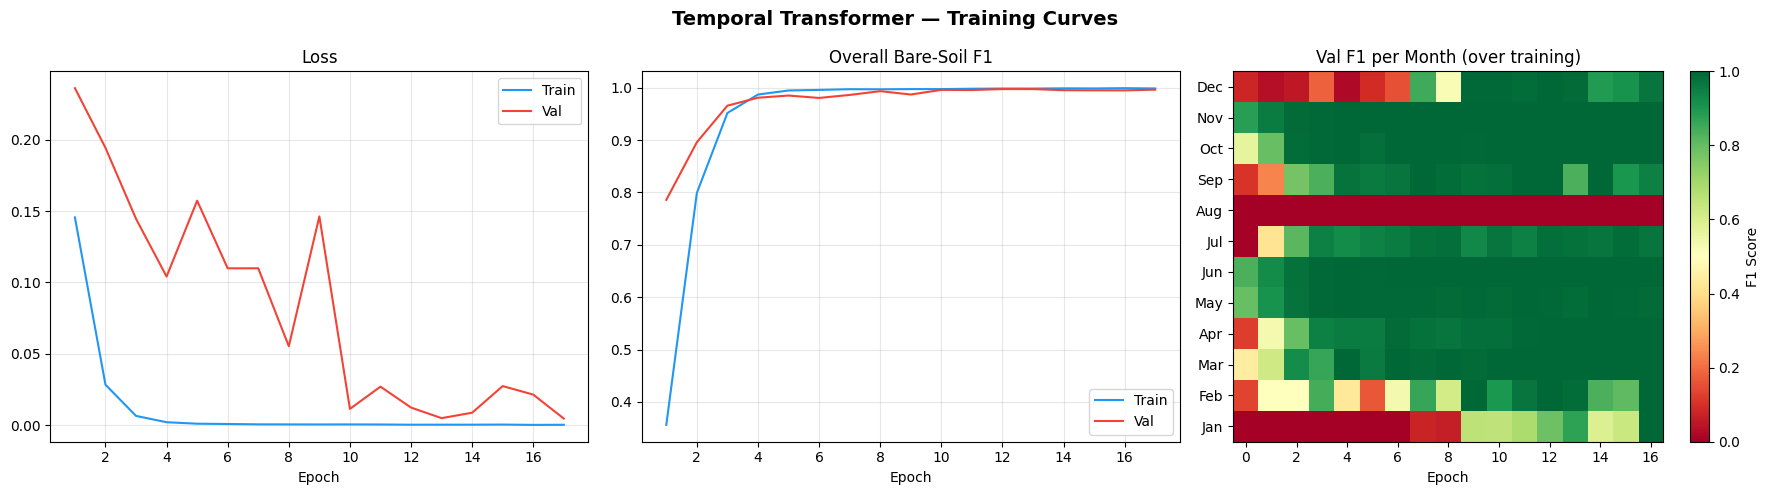

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Temporal Transformer — Training Curves', fontsize=14, fontweight='bold')

eps = range(1, len(history['train_loss']) + 1)

axes[0].plot(eps, history['train_loss'], label='Train', color='#2196F3')
axes[0].plot(eps, history['val_loss'],   label='Val',   color='#F44336')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(eps, history['train_f1'], label='Train', color='#2196F3')
axes[1].plot(eps, history['val_f1'],   label='Val',   color='#F44336')
axes[1].set_title('Overall Bare-Soil F1')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Per-month F1 evolution over training (heatmap)
monthly_f1_matrix = np.array(history['val_f1_per_month'])   # (epochs, 12)
im = axes[2].imshow(monthly_f1_matrix.T, aspect='auto', cmap='RdYlGn',
                    vmin=0, vmax=1, origin='lower')
axes[2].set_yticks(range(N_MONTHS))
axes[2].set_yticklabels([m[:3] for m in MONTHS])
axes[2].set_xlabel('Epoch')
axes[2].set_title('Val F1 per Month (over training)')
plt.colorbar(im, ax=axes[2], label='F1 Score')

plt.tight_layout()
plt.savefig(f'{BASE_DIR}training_curves_temporal.png', dpi=120)
plt.show()

## 9. Evaluation — Per-Month Breakdown

In [ ]:
# ── Final evaluation on Amritsar (test) ──────────────────────
model.eval()
all_preds  = []
all_labels = []

with torch.no_grad():
    for x_batch, y_batch in tqdm(va_loader, desc='Evaluating'):
        x_batch = x_batch.to(DEVICE)
        logits  = model(x_batch)                    # (B, 12, 2)
        preds   = logits.argmax(dim=-1).cpu().numpy()  # (B, 12)
        all_preds.append(preds)
        all_labels.append(y_batch.numpy())

all_preds  = np.concatenate(all_preds,  axis=0)    # (N_test, 12)
all_labels = np.concatenate(all_labels, axis=0)

print('─'*60)
print('  OVERALL CLASSIFICATION REPORT (all months flattened)')
print('─'*60)
print(classification_report(
    all_labels.flatten(), all_preds.flatten(),
    target_names=['Crop', 'Bare Soil']
))

Evaluating:   0%|          | 0/412 [00:00<?, ?it/s]

────────────────────────────────────────────────────────────
  OVERALL CLASSIFICATION REPORT (all months flattened)
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

        Crop       1.00      1.00      1.00   2328199
   Bare Soil       1.00      1.00      1.00    200549

    accuracy                           1.00   2528748
   macro avg       1.00      1.00      1.00   2528748
weighted avg       1.00      1.00      1.00   2528748



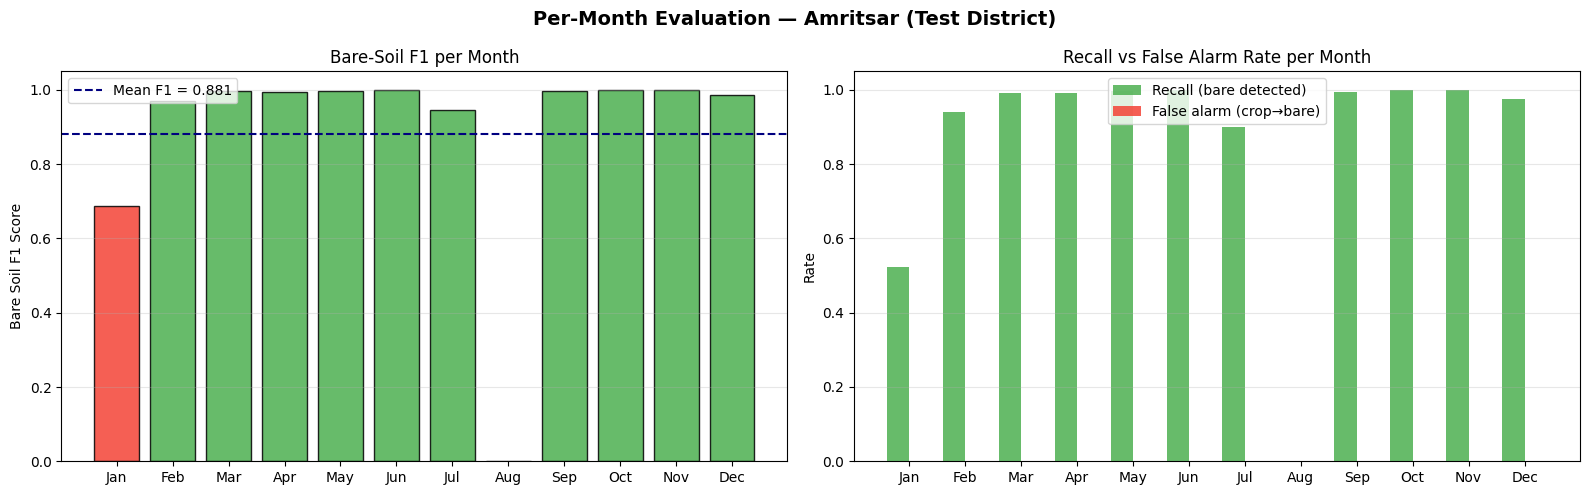


Per-month F1 scores:
       January: 0.6868  █████████████
      February: 0.9690  ███████████████████
         March: 0.9962  ███████████████████
         April: 0.9956  ███████████████████
           May: 0.9965  ███████████████████
          June: 0.9999  ███████████████████
          July: 0.9472  ██████████████████
        August: 0.0000  
     September: 0.9971  ███████████████████
       October: 0.9999  ███████████████████
      November: 1.0000  ███████████████████
      December: 0.9873  ███████████████████


In [ ]:
# ── Per-month F1 bar chart ────────────────────────────────────
monthly_f1_final = np.array([
    f1_score(all_labels[:, m], all_preds[:, m], pos_label=1, zero_division=0)
    for m in range(N_MONTHS)
])

monthly_precision = np.array([
    f1_score(all_labels[:, m], all_preds[:, m], pos_label=1,
             average='binary', zero_division=0)
    for m in range(N_MONTHS)
])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Per-Month Evaluation — Amritsar (Test District)', fontsize=14, fontweight='bold')

# F1 per month
colors = ['#F44336' if f < 0.7 else '#FF9800' if f < 0.85 else '#4CAF50'
          for f in monthly_f1_final]
axes[0].bar(range(N_MONTHS), monthly_f1_final, color=colors, edgecolor='black', alpha=0.85)
axes[0].axhline(monthly_f1_final.mean(), color='navy', linestyle='--',
                label=f'Mean F1 = {monthly_f1_final.mean():.3f}')
axes[0].set_xticks(range(N_MONTHS))
axes[0].set_xticklabels([m[:3] for m in MONTHS])
axes[0].set_ylabel('Bare Soil F1 Score')
axes[0].set_title('Bare-Soil F1 per Month')
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Confusion matrix — heatmap across months
# For each month: [[TN, FP], [FN, TP]]
cms = np.array([
    confusion_matrix(all_labels[:, m], all_preds[:, m], labels=[0, 1])
    for m in range(N_MONTHS)
])  # (12, 2, 2)

# Plot TP rate and FP rate per month
tp_rates = cms[:, 1, 1] / (cms[:, 1, 0] + cms[:, 1, 1] + 1e-8)   # recall
fp_rates = cms[:, 0, 1] / (cms[:, 0, 0] + cms[:, 0, 1] + 1e-8)   # false alarm

x = np.arange(N_MONTHS)
axes[1].bar(x - 0.2, tp_rates, 0.4, label='Recall (bare detected)',   color='#4CAF50', alpha=0.85)
axes[1].bar(x + 0.2, fp_rates, 0.4, label='False alarm (crop→bare)', color='#F44336', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels([m[:3] for m in MONTHS])
axes[1].set_ylabel('Rate')
axes[1].set_title('Recall vs False Alarm Rate per Month')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}eval_per_month.png', dpi=120)
plt.show()

print('\nPer-month F1 scores:')
for m, f1 in zip(MONTHS, monthly_f1_final):
    bar = '█' * int(f1 * 20)
    print(f'  {m:>12}: {f1:.4f}  {bar}')

## 10. 🔬 Attention Visualization — What Is the Model Learning?

This is the core of the "understand" goal.

We pick example pixels and visualize:
1. Their NDVI profile over 12 months
2. Their true label per month
3. The model's attention — which months does it look at to make each prediction?

In [ ]:
def visualize_pixel_attention(model, X_scaled, y_labels, pixel_indices,
                               title='Attention Visualization'):
    """
    For each pixel index in pixel_indices, plots:
      Row 1: NDVI over 12 months + true labels
      Row 2: Attention heatmap (heads averaged) — which month attends to which
      Row 3: Model predictions vs true labels per month
    """
    model.eval()
    n_pixels = len(pixel_indices)
    fig, axes = plt.subplots(3, n_pixels, figsize=(5 * n_pixels, 12))
    if n_pixels == 1:
        axes = axes.reshape(-1, 1)
    fig.suptitle(title, fontsize=14, fontweight='bold')

    month_labels = [m[:3] for m in MONTHS]

    for col, pidx in enumerate(pixel_indices):
        x_raw = X_scaled[pidx]              # (12, 10)
        y_raw = y_labels[pidx]              # (12,)

        x_t = torch.from_numpy(x_raw).unsqueeze(0).to(DEVICE)   # (1, 12, 10)

        with torch.no_grad():
            logits  = model(x_t)                     # (1, 12, 2)
            preds   = logits.argmax(dim=-1).cpu().numpy()[0]  # (12,)
            attn_w  = model.get_attention_weights(x_t)  # (1, n_heads, 12, 12)

        if attn_w is not None:
            attn_avg = attn_w[0].mean(dim=0).cpu().numpy()  # (12, 12) head-averaged
        else:
            attn_avg = np.eye(N_MONTHS)  # fallback

        # Compute NDVI from unscaled data (use original X_train/X_test)
        # x_raw is scaled — approximate NDVI from scaled values
        b4 = x_raw[:, BAND_COLS.index('B4')]
        b8 = x_raw[:, BAND_COLS.index('B8')]
        ndvi_approx = (b8 - b4) / (b8 + b4 + 1e-8)

        # ── Row 0: NDVI profile + labels ─────────────────────
        ax0 = axes[0, col]
        ax0.plot(ndvi_approx, 'o-', color='#2196F3', linewidth=2, label='NDVI (scaled)')
        # Shade bare soil months
        for m in range(N_MONTHS):
            if y_raw[m] == 1:
                ax0.axvspan(m - 0.5, m + 0.5, alpha=0.25, color='#F44336', label='Bare (true)' if m == np.where(y_raw == 1)[0][0] else '')
        ax0.set_xticks(range(N_MONTHS))
        ax0.set_xticklabels(month_labels, rotation=45, fontsize=8)
        ax0.set_title(f'Pixel {pidx}\nNDVI Profile', fontsize=10)
        ax0.set_ylabel('Scaled NDVI')
        ax0.legend(fontsize=7)
        ax0.grid(alpha=0.3)

        # ── Row 1: Attention heatmap ──────────────────────────
        ax1 = axes[1, col]
        im = ax1.imshow(attn_avg, cmap='Blues', vmin=0, aspect='auto')
        ax1.set_xticks(range(N_MONTHS))
        ax1.set_yticks(range(N_MONTHS))
        ax1.set_xticklabels(month_labels, rotation=45, fontsize=7)
        ax1.set_yticklabels(month_labels, fontsize=7)
        ax1.set_title('Attention Weights\n(row=query month, col=key month)', fontsize=9)
        ax1.set_xlabel('Key (attends to)')
        ax1.set_ylabel('Query (being predicted)')
        plt.colorbar(im, ax=ax1, fraction=0.046)

        # Highlight bare soil months on attention map
        for m in range(N_MONTHS):
            if y_raw[m] == 1:
                ax1.axhline(m, color='red',   linewidth=1.5, alpha=0.6)
                ax1.axvline(m, color='orange', linewidth=1.5, alpha=0.6)

        # ── Row 2: Prediction vs truth per month ──────────────
        ax2 = axes[2, col]
        x_pos = np.arange(N_MONTHS)
        ax2.bar(x_pos - 0.2, y_raw,  0.4, label='True',      color='#4CAF50', alpha=0.8)
        ax2.bar(x_pos + 0.2, preds,  0.4, label='Predicted', color='#FF9800', alpha=0.8)
        ax2.set_xticks(x_pos)
        ax2.set_xticklabels(month_labels, rotation=45, fontsize=8)
        ax2.set_yticks([0, 1])
        ax2.set_yticklabels(['Crop', 'Bare'])
        ax2.set_title('True vs Predicted Labels', fontsize=9)
        ax2.legend(fontsize=8)
        ax2.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    return fig


print('Visualization function defined.')

Visualization function defined.


In [ ]:
# ── Select interesting pixels for visualization ───────────────
# Find pixels with different temporal patterns:
#   (a) Bare only in Rabi window (Nov-Feb)
#   (b) Bare only in Kharif window (May-Sep)
#   (c) Bare in multiple windows
#   (d) Always crop

rabi_months   = [MONTHS.index(m) for m in ['November', 'December', 'January', 'February']]
kharif_months = [MONTHS.index(m) for m in ['May', 'June', 'July', 'August']]

def find_pixel_type(y, months_of_interest, min_bare=1, max_bare_outside=1):
    """Find pixels that are bare in months_of_interest and rarely bare elsewhere."""
    outside = [m for m in range(N_MONTHS) if m not in months_of_interest]
    candidates = np.where(
        (y[:, months_of_interest].sum(axis=1) >= min_bare) &
        (y[:, outside].sum(axis=1) <= max_bare_outside)
    )[0]
    return candidates

rabi_pixels   = find_pixel_type(y_test, rabi_months)
kharif_pixels = find_pixel_type(y_test, kharif_months)
always_crop   = np.where(y_test.sum(axis=1) == 0)[0]
double_bare   = np.where(y_test.sum(axis=1) >= 6)[0]

print(f'Rabi-window bare pixels   : {len(rabi_pixels):,}')
print(f'Kharif-window bare pixels : {len(kharif_pixels):,}')
print(f'Always-crop pixels        : {len(always_crop):,}')
print(f'Double-season bare pixels : {len(double_bare):,}')

rng = np.random.default_rng(SEED)

# Pick one example of each type
sample_pixels = []
for arr, name in [
    (rabi_pixels,   'Rabi bare'),
    (kharif_pixels, 'Kharif bare'),
    (always_crop,   'Always crop'),
    (double_bare,   'Double season'),
]:
    if len(arr) > 0:
        sample_pixels.append(rng.choice(arr))
        print(f'  Selected {name}: pixel {sample_pixels[-1]}')

print(f'\nVisualizing {len(sample_pixels)} pixels...')

Rabi-window bare pixels   : 8,702
Kharif-window bare pixels : 69,860
Always-crop pixels        : 124,515
Double-season bare pixels : 28
  Selected Rabi bare: pixel 27395
  Selected Kharif bare: pixel 166212
  Selected Always crop: pixel 135931
  Selected Double season: pixel 112626

Visualizing 4 pixels...


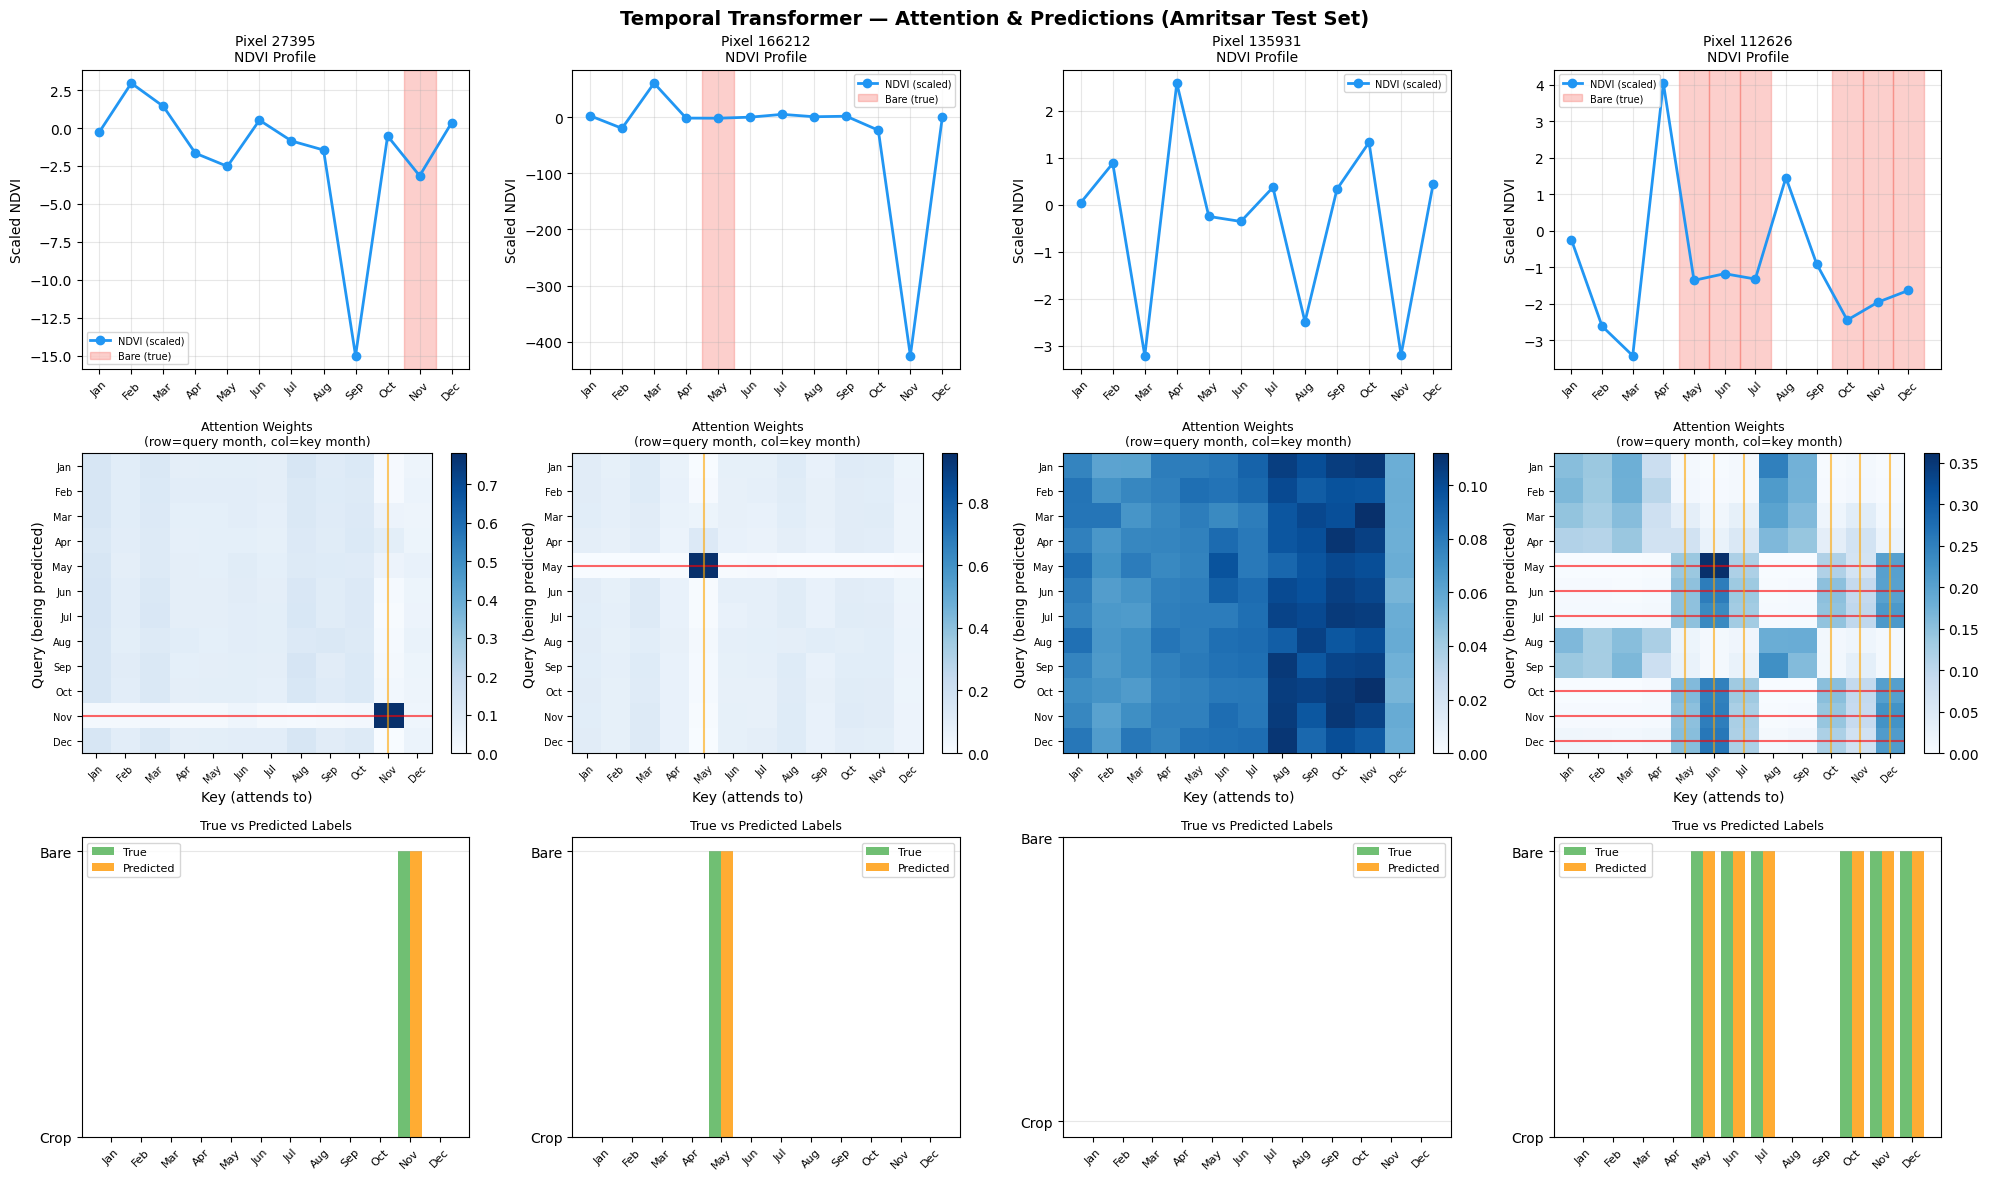


💡 Reading the attention heatmap:
  - Row = the month being predicted
  - Col = the month being attended to
  - Bright cell at (May_row, Apr_col) = "To predict May, model looks at April"
  - Red lines mark true bare soil months
  - Orange lines mark same months on key axis
  If the model learned the crop cycle, you should see:
  attention concentrated around the transition months adjacent to bare windows.


In [ ]:
fig = visualize_pixel_attention(
    model, X_va_scaled, y_test,
    pixel_indices=sample_pixels,
    title='Temporal Transformer — Attention & Predictions (Amritsar Test Set)'
)
fig.savefig(f'{BASE_DIR}attention_visualization.png', dpi=120, bbox_inches='tight')
plt.show()
print('\n💡 Reading the attention heatmap:')
print('  - Row = the month being predicted')
print('  - Col = the month being attended to')
print('  - Bright cell at (May_row, Apr_col) = "To predict May, model looks at April"')
print('  - Red lines mark true bare soil months')
print('  - Orange lines mark same months on key axis')
print('  If the model learned the crop cycle, you should see:')
print('  attention concentrated around the transition months adjacent to bare windows.')

## 11. 📊 Aggregate Attention Analysis

Average attention across ALL bare-soil pixels — reveals which temporal context the model relies on most.

Computing average attention for bare-soil pixels...
Computing average attention for crop pixels...


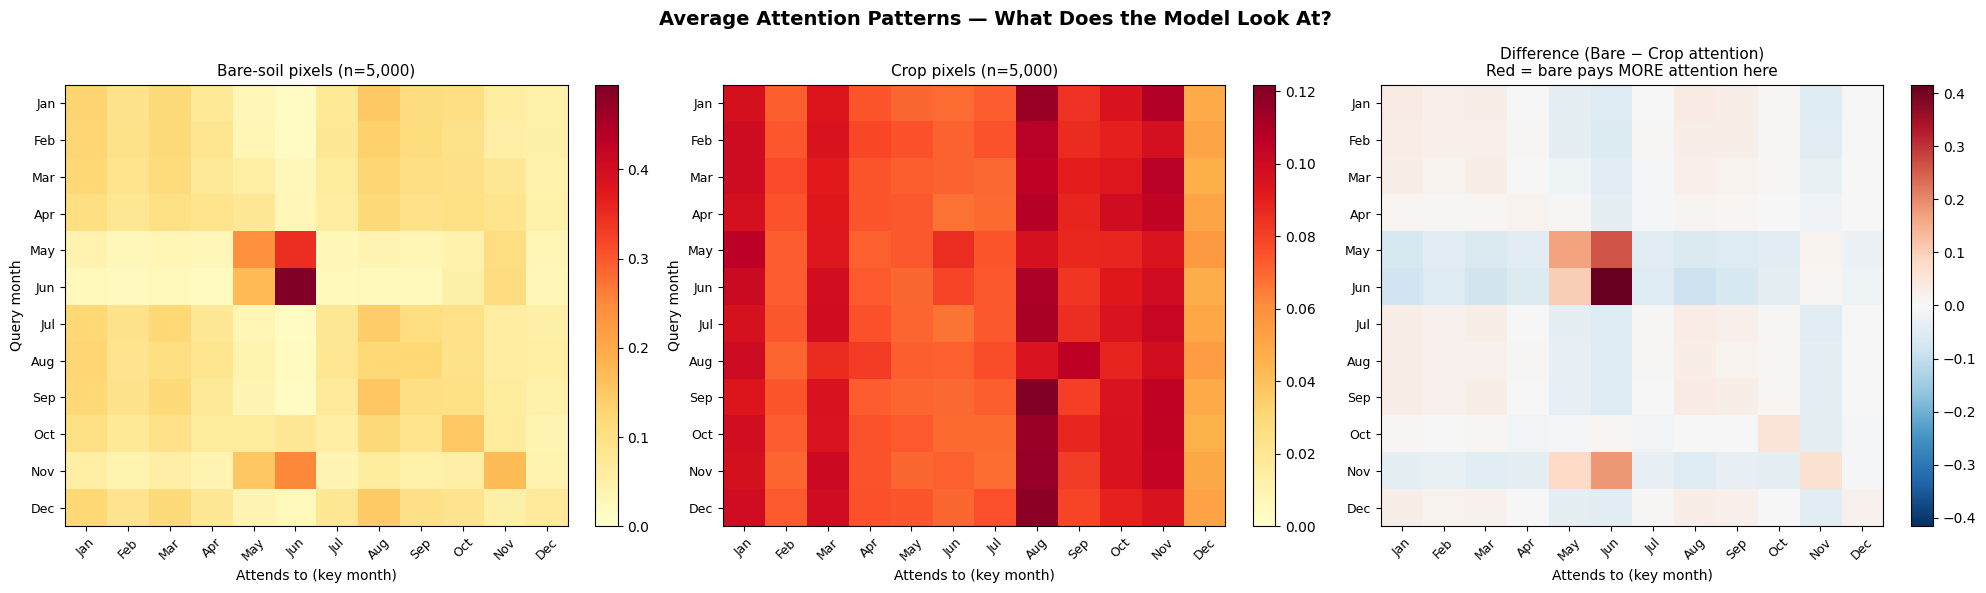

✅ Red cells in the difference plot show temporal context unique to bare soil detection.


In [ ]:
# ── Compute average attention for bare vs crop pixels ─────────
# Sample 5000 pixels of each type for efficiency
N_SAMPLE = 5000

bare_dominant  = np.where(y_test.sum(axis=1) >= 1)[0]
crop_dominant  = np.where(y_test.sum(axis=1) == 0)[0]

bare_sample = rng.choice(bare_dominant,  min(N_SAMPLE, len(bare_dominant)),  replace=False)
crop_sample = rng.choice(crop_dominant,  min(N_SAMPLE, len(crop_dominant)),  replace=False)

def compute_avg_attention(model, X_scaled, indices, batch_size=256):
    """Average attention weights over a set of pixel indices."""
    model.eval()
    attn_sum = np.zeros((N_MONTHS, N_MONTHS), dtype=np.float64)
    count = 0
    for start in range(0, len(indices), batch_size):
        batch_idx = indices[start:start + batch_size]
        x_batch = torch.from_numpy(X_scaled[batch_idx]).to(DEVICE)
        with torch.no_grad():
            attn_w = model.get_attention_weights(x_batch)   # (B, heads, 12, 12)
        if attn_w is not None:
            attn_sum += attn_w.mean(dim=1).cpu().numpy().sum(axis=0)  # sum over batch
            count += len(batch_idx)
    return attn_sum / (count + 1e-8)

print('Computing average attention for bare-soil pixels...')
attn_bare = compute_avg_attention(model, X_va_scaled, bare_sample)
print('Computing average attention for crop pixels...')
attn_crop = compute_avg_attention(model, X_va_scaled, crop_sample)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Average Attention Patterns — What Does the Model Look At?',
             fontsize=14, fontweight='bold')

month_abbr = [m[:3] for m in MONTHS]

for ax, (data, title) in zip(axes[:2], [
    (attn_bare, f'Bare-soil pixels (n={len(bare_sample):,})'),
    (attn_crop, f'Crop pixels (n={len(crop_sample):,})'),
]):
    im = ax.imshow(data, cmap='YlOrRd', vmin=0, aspect='auto')
    ax.set_xticks(range(N_MONTHS))
    ax.set_yticks(range(N_MONTHS))
    ax.set_xticklabels(month_abbr, rotation=45, fontsize=9)
    ax.set_yticklabels(month_abbr, fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Attends to (key month)')
    ax.set_ylabel('Query month')
    plt.colorbar(im, ax=ax, fraction=0.046)

# Difference: bare - crop attention
attn_diff = attn_bare - attn_crop
vmax = np.abs(attn_diff).max()
im = axes[2].imshow(attn_diff, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[2].set_xticks(range(N_MONTHS))
axes[2].set_yticks(range(N_MONTHS))
axes[2].set_xticklabels(month_abbr, rotation=45, fontsize=9)
axes[2].set_yticklabels(month_abbr, fontsize=9)
axes[2].set_title('Difference (Bare − Crop attention)\nRed = bare pays MORE attention here', fontsize=11)
axes[2].set_xlabel('Attends to (key month)')
plt.colorbar(im, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}avg_attention_analysis.png', dpi=120)
plt.show()
print('✅ Red cells in the difference plot show temporal context unique to bare soil detection.')

## 12. Save Model & Final Summary

In [ ]:
# ── Save ─────────────────────────────────────────────────────
import joblib

torch.save(model.state_dict(), f'{BASE_DIR}temporal_transformer.pt')
joblib.dump(scaler, f'{BASE_DIR}temporal_scaler.joblib')

print('Saved:')
print(f'  {BASE_DIR}temporal_transformer.pt')
print(f'  {BASE_DIR}temporal_scaler.joblib')

# ── Summary ───────────────────────────────────────────────────
print('\n' + '═'*60)
print('  FINAL RESULTS SUMMARY')
print('═'*60)
print(f'  Model        : Temporal Transformer (seq2seq)')
print(f'  Input        : (12 months × 10 bands) per pixel')
print(f'  Output       : label per month (crop / bare)')
print(f'  Train        : Patiala  ({N_train:,} pixels)')
print(f'  Test         : Amritsar ({N_test:,} pixels)')
print(f'  Best val F1  : {best_f1:.4f}')
print()
print(f'  Per-month F1 (Amritsar):')
for m, f1 in zip(MONTHS, monthly_f1_final):
    bar = '█' * int(f1 * 20)
    flag = ' ← bare window' if monthly_f1_final[MONTHS.index(m)] == monthly_f1_final.max() else ''
    print(f'    {m:>12}: {f1:.4f}  {bar}{flag}')
print('═'*60)

Saved:
  /content/drive/MyDrive/ILGC-V/temporal_transformer.pt
  /content/drive/MyDrive/ILGC-V/temporal_scaler.joblib

════════════════════════════════════════════════════════════
  FINAL RESULTS SUMMARY
════════════════════════════════════════════════════════════
  Model        : Temporal Transformer (seq2seq)
  Input        : (12 months × 10 bands) per pixel
  Output       : label per month (crop / bare)
  Train        : Patiala  (319,408 pixels)
  Test         : Amritsar (210,729 pixels)
  Best val F1  : 0.9974

  Per-month F1 (Amritsar):
         January: 0.6868  █████████████
        February: 0.9690  ███████████████████
           March: 0.9962  ███████████████████
           April: 0.9956  ███████████████████
             May: 0.9965  ███████████████████
            June: 0.9999  ███████████████████
            July: 0.9472  ██████████████████
          August: 0.0000  
       September: 0.9971  ███████████████████
         October: 0.9999  ███████████████████
        November: 